# 导星单星 stamp 饱和评估：QE=0.7、光学透过率=0.7 分支

本 notebook 使用与基线报告完全一致的 31x31 单星 stamp 仿真链路，但将量子效率和光学透过率共同乘到单星光电子数与天光背景光电子数上。暗电流、杂散光、读出噪声、满阱、偏置和 ADC 参数保持不变。

分支设置：$\eta_\mathrm{QE}=0.7$，$T_\mathrm{optics}=0.7$，总光子效率 $\eta=0.49$。

In [1]:
from pathlib import Path
import json
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path('/home/liyang/ET7/ET-fsgsim')
BASELINE_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep')
BRANCH_DIR = Path('/home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep_qe0p7_throughput0p7')
SWEEP_SCRIPT = REPO_ROOT / 'scripts' / 'guide_stamp_saturation_sweep.py'
ASSET_DIR = REPO_ROOT / 'notebooks' / 'guide_star_saturation_qe0p7_throughput0p7_files'
ASSET_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_SUMMARY_CSV = BASELINE_DIR / 'saturation_summary.csv'
BASELINE_METADATA_JSON = BASELINE_DIR / 'saturation_metadata.json'
BRANCH_SUMMARY_CSV = BRANCH_DIR / 'saturation_summary.csv'
BRANCH_METADATA_JSON = BRANCH_DIR / 'saturation_metadata.json'
BRANCH_STAMPS_NPZ = BRANCH_DIR / 'single_star_stamps_31x31.npz'

plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 200,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

for path in [BASELINE_SUMMARY_CSV, BASELINE_METADATA_JSON, BRANCH_SUMMARY_CSV, BRANCH_METADATA_JSON, BRANCH_STAMPS_NPZ, SWEEP_SCRIPT]:
    if not path.exists():
        raise FileNotFoundError(path)

print(f'Baseline result directory: {BASELINE_DIR}')
print(f'Branch result directory: {BRANCH_DIR}')

Baseline result directory: /home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep
Branch result directory: /home/liyang/ET7/Results/FSG_guide_sims/single_star_saturation_sweep_qe0p7_throughput0p7


## 分支模型

基线单星光电子数为：

$$N_\star(m)=R_\star(m)t_\mathrm{exp}$$

本分支将量子效率和光学透过率乘到单星与天光背景产生的光电子数上：

$$N'_\star(m)=N_\star(m)\,\eta_\mathrm{QE}\,T_\mathrm{optics}=0.49N_\star(m)$$

$$N'_\mathrm{bg}=N_\mathrm{bg}\,\eta_\mathrm{QE}\,T_\mathrm{optics}=0.49N_\mathrm{bg}$$

暗电流、杂散光和读出噪声不是入射光子链路产生的天光或目标星光电子，因此在本分支中不乘 0.49。饱和判据仍为满阱裁剪前像素电荷 $Q\ge1800\,e^-$。

In [2]:
baseline = pd.read_csv(BASELINE_SUMMARY_CSV)
branch = pd.read_csv(BRANCH_SUMMARY_CSV)
with BASELINE_METADATA_JSON.open('r', encoding='utf-8') as handle:
    baseline_meta = json.load(handle)
with BRANCH_METADATA_JSON.open('r', encoding='utf-8') as handle:
    branch_meta = json.load(handle)
stamps = np.load(BRANCH_STAMPS_NPZ)

for df in [baseline, branch]:
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='ignore')

baseline['photon_efficiency'] = baseline.get('photon_efficiency', 1.0)
baseline_meta.setdefault('quantum_efficiency', 1.0)
baseline_meta.setdefault('optical_throughput', 1.0)
baseline_meta.setdefault('photon_efficiency', 1.0)
baseline_meta.setdefault('background_flux_e_per_s_per_pix_before_efficiency', baseline_meta['background_flux_e_per_s_per_pix'])

print(f"Baseline first any saturation mag: {baseline_meta['first_mag_with_any_saturated_realization']}")
print(f"Branch first any saturation mag: {branch_meta['first_mag_with_any_saturated_realization']}")
print(f"Branch photon efficiency: {branch_meta['photon_efficiency']:.3f}")

Baseline first any saturation mag: 10.5
Branch first any saturation mag: 9.5
Branch photon efficiency: 0.490


/tmp/ipykernel_2374440/3440587559.py:11: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df[col] = pd.to_numeric(df[col], errors='ignore')


In [3]:
param_rows = [
    ('Quantum efficiency', baseline_meta['quantum_efficiency'], branch_meta['quantum_efficiency']),
    ('Optical throughput', baseline_meta['optical_throughput'], branch_meta['optical_throughput']),
    ('Photon efficiency product', baseline_meta['photon_efficiency'], branch_meta['photon_efficiency']),
    ('Applied to', 'stellar, sky background', ', '.join(branch_meta['photon_efficiency_applied_to'])),
    ('Background flux before efficiency (e/s/pix)', baseline_meta['background_flux_e_per_s_per_pix_before_efficiency'], branch_meta['background_flux_e_per_s_per_pix_before_efficiency']),
    ('Background flux used (e/s/pix)', baseline_meta['background_flux_e_per_s_per_pix'], branch_meta['background_flux_e_per_s_per_pix']),
    ('Background count per frame (e/pix)', baseline_meta['background_counts_e_per_pix'], branch_meta['background_counts_e_per_pix']),
    ('Dark current count per frame (e/pix)', baseline_meta['dark_counts_e_per_pix'], branch_meta['dark_counts_e_per_pix']),
    ('Scattered light count per frame (e/pix)', baseline_meta['scattered_counts_e_per_pix'], branch_meta['scattered_counts_e_per_pix']),
    ('Readout noise (e/pix)', baseline_meta['readout_noise_e_per_pix'], branch_meta['readout_noise_e_per_pix']),
    ('Full well (e)', baseline_meta['full_well_electrons'], branch_meta['full_well_electrons']),
    ('Realizations per mag', baseline_meta['n_realizations_per_mag'], branch_meta['n_realizations_per_mag']),
]
param_df = pd.DataFrame(param_rows, columns=['Parameter', 'Baseline', 'QE0.7 throughput0.7'])
display(param_df)
param_df.to_csv(ASSET_DIR / 'qe_branch_parameter_comparison.csv', index=False)

,Parameter,Baseline,QE0.7 throughput0.7
0,Quantum efficiency,1.0,0.7
1,Optical throughput,1.0,0.7
2,Photon efficiency product,1.0,0.49
3,Applied to,"stellar, sky background","stellar, sky_background"
4,Background flux before efficiency (e/s/pix),17.41167,17.41167
5,Background flux used (e/s/pix),17.41167,8.531718
6,Background count per frame (e/pix),4.352917,2.13293
7,Dark current count per frame (e/pix),1.25,1.25
8,Scattered light count per frame (e/pix),1.25,1.25
9,Readout noise (e/pix),5.0,5.0


,mag,baseline photo-electrons / 0.25 s,branch pre-efficiency photo-electrons / 0.25 s,branch photo-electrons / 0.25 s,branch rendered PSF stamp sum (e),branch / baseline
0,14.0,697.0,697.0,341.6,341.6,0.490
1,13.5,1104.7,1104.7,541.3,541.3,0.490
2,13.0,1750.9,1750.9,857.9,857.9,0.490
3,12.5,2775.0,2775.0,1359.8,1359.8,0.490
4,12.0,4398.1,4398.1,2155.1,2155.1,0.490
5,11.5,6970.5,6970.5,3415.5,3415.5,0.490
6,11.0,11047.5,11047.5,5413.3,5413.3,0.490
7,10.5,17509.1,17509.1,8579.4,8579.4,0.490
8,10.0,27750.0,27750.0,13597.5,13597.5,0.490
9,9.5,43980.8,43980.8,21550.6,21550.6,0.490


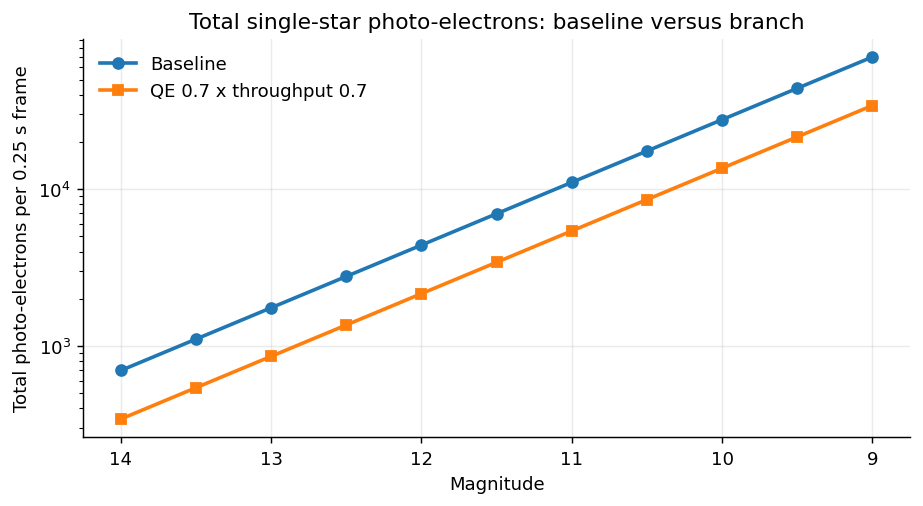

In [4]:
photon_compare = baseline[['mag', 'photon_count_e_0p25s']].rename(columns={
    'photon_count_e_0p25s': 'baseline photo-electrons / 0.25 s',
}).merge(
    branch[['mag', 'base_photon_count_e_0p25s', 'photon_count_e_0p25s', 'expected_total_star_e']].rename(columns={
        'base_photon_count_e_0p25s': 'branch pre-efficiency photo-electrons / 0.25 s',
        'photon_count_e_0p25s': 'branch photo-electrons / 0.25 s',
        'expected_total_star_e': 'branch rendered PSF stamp sum (e)',
    }),
    on='mag',
)
photon_compare['branch / baseline'] = photon_compare['branch photo-electrons / 0.25 s'] / photon_compare['baseline photo-electrons / 0.25 s']
display(photon_compare.style.format({
    'mag': '{:.1f}',
    'baseline photo-electrons / 0.25 s': '{:.1f}',
    'branch pre-efficiency photo-electrons / 0.25 s': '{:.1f}',
    'branch photo-electrons / 0.25 s': '{:.1f}',
    'branch rendered PSF stamp sum (e)': '{:.1f}',
    'branch / baseline': '{:.3f}',
}).background_gradient(subset=['branch photo-electrons / 0.25 s'], cmap='Blues'))
photon_compare.to_csv(ASSET_DIR / 'qe_branch_total_photoelectron_comparison.csv', index=False)

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(photon_compare['mag'], photon_compare['baseline photo-electrons / 0.25 s'], marker='o', lw=2, label='Baseline')
ax.plot(photon_compare['mag'], photon_compare['branch photo-electrons / 0.25 s'], marker='s', lw=2, label='QE 0.7 x throughput 0.7')
ax.set_yscale('log')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Total photo-electrons per 0.25 s frame')
ax.set_title('Total single-star photo-electrons: baseline versus branch')
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'qe_branch_total_photoelectrons_vs_mag.png', bbox_inches='tight')
plt.show()


In [5]:
report_cols = [
    'mag', 'photon_count_e_0p25s', 'expected_peak_star_e',
    'max_charge_e_median', 'max_charge_e_p95', 'max_charge_e_max',
    'saturated_frames', 'saturation_fraction', 'max_saturated_pixels_in_frame',
]
branch_report = branch[report_cols].rename(columns={
    'photon_count_e_0p25s': 'branch total star e / frame',
    'expected_peak_star_e': 'expected peak e',
    'max_charge_e_median': 'median max charge e',
    'max_charge_e_p95': 'p95 max charge e',
    'max_charge_e_max': 'max charge e',
    'saturated_frames': 'sat frames',
    'saturation_fraction': 'sat fraction',
    'max_saturated_pixels_in_frame': 'max sat pix/frame',
})
display(branch_report.style.format({
    'mag': '{:.1f}',
    'branch total star e / frame': '{:.1f}',
    'expected peak e': '{:.1f}',
    'median max charge e': '{:.1f}',
    'p95 max charge e': '{:.1f}',
    'max charge e': '{:.1f}',
    'sat fraction': '{:.3f}',
}).background_gradient(subset=['sat fraction'], cmap='Reds'))
branch_report.to_csv(ASSET_DIR / 'qe_branch_saturation_report_table.csv', index=False)

,mag,branch total star e / frame,expected peak e,median max charge e,p95 max charge e,max charge e,sat frames,sat fraction,max sat pix/frame
0,14.0,341.6,32.3,37.0,47.0,56.0,0,0.000,0
1,13.5,541.3,51.3,56.0,68.0,78.0,0,0.000,0
2,13.0,857.9,81.3,85.0,103.0,117.0,0,0.000,0
3,12.5,1359.8,128.8,133.0,153.0,169.0,0,0.000,0
4,12.0,2155.1,204.1,209.0,232.0,251.0,0,0.000,0
5,11.5,3415.5,323.5,329.0,358.0,389.0,0,0.000,0
6,11.0,5413.3,512.7,516.0,556.0,582.0,0,0.000,0
7,10.5,8579.4,812.5,821.0,862.1,917.0,0,0.000,0
8,10.0,13597.5,1287.8,1296.0,1351.0,1407.0,0,0.000,0
9,9.5,21550.6,2041.0,2043.5,2119.1,2182.0,500,1.000,1


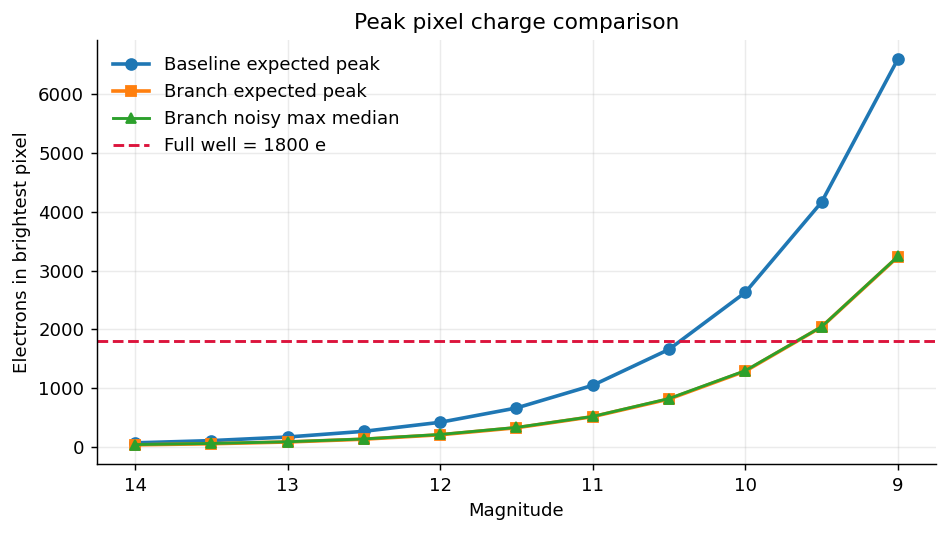

In [6]:
full_well = float(branch_meta['full_well_electrons'])
fig, ax = plt.subplots(figsize=(7.4, 4.2))
ax.plot(baseline['mag'], baseline['expected_peak_star_e'], marker='o', lw=2, label='Baseline expected peak')
ax.plot(branch['mag'], branch['expected_peak_star_e'], marker='s', lw=2, label='Branch expected peak')
ax.plot(branch['mag'], branch['max_charge_e_median'], marker='^', lw=1.6, label='Branch noisy max median')
ax.axhline(full_well, color='crimson', ls='--', lw=1.6, label='Full well = 1800 e')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Electrons in brightest pixel')
ax.set_title('Peak pixel charge comparison')
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'qe_branch_peak_charge_comparison.png', bbox_inches='tight')
plt.show()

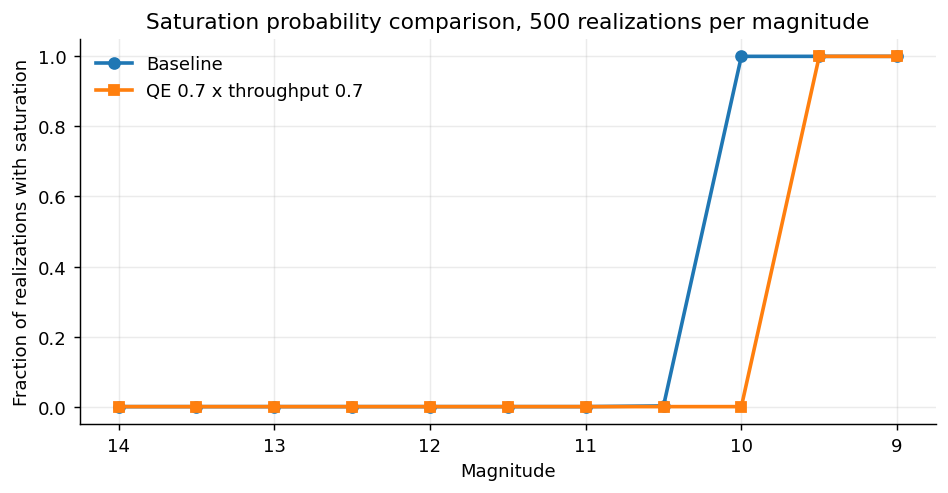

In [7]:
fig, ax = plt.subplots(figsize=(7.4, 3.9))
ax.plot(baseline['mag'], baseline['saturation_fraction'], marker='o', lw=2, label='Baseline')
ax.plot(branch['mag'], branch['saturation_fraction'], marker='s', lw=2, label='QE 0.7 x throughput 0.7')
ax.set_xlabel('Magnitude')
ax.set_ylabel('Fraction of realizations with saturation')
ax.set_title('Saturation probability comparison, 500 realizations per magnitude')
ax.set_ylim(-0.05, 1.05)
ax.invert_xaxis()
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'qe_branch_saturation_fraction_comparison.png', bbox_inches='tight')
plt.show()

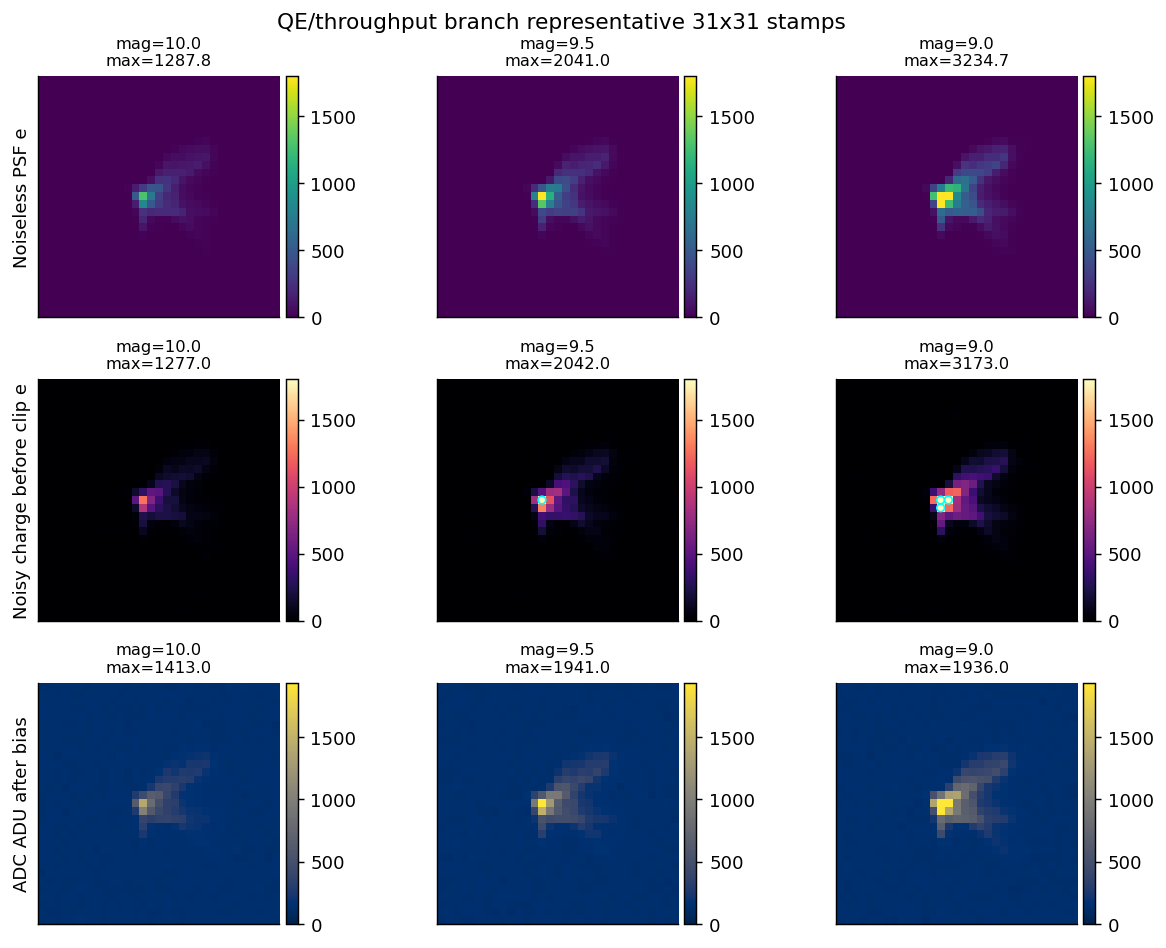

In [8]:
selected_mags = [10.0, 9.5, 9.0]
fig, axes = plt.subplots(3, len(selected_mags), figsize=(9.2, 7.0), constrained_layout=True)
row_specs = [
    ('expected_star_e', 'Noiseless PSF e', 'viridis', full_well),
    ('charge_before_clip_e', 'Noisy charge before clip e', 'magma', full_well),
    ('adc_adu', 'ADC ADU after bias', 'cividis', full_well + branch_meta['bias_level_adu']),
]
for col, mag in enumerate(selected_mags):
    for row, (suffix, label, cmap, vmax) in enumerate(row_specs):
        key = f'mag_{mag:.1f}_{suffix}'
        image = stamps[key]
        ax = axes[row, col]
        im = ax.imshow(image, origin='lower', cmap=cmap, vmin=0, vmax=vmax)
        if suffix == 'charge_before_clip_e':
            saturated = image >= full_well
            if np.any(saturated):
                yy, xx = np.where(saturated)
                ax.scatter(xx, yy, s=18, facecolors='none', edgecolors='cyan', linewidths=0.9)
        ax.set_title(f'mag={mag:.1f}\nmax={np.nanmax(image):.1f}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(label)
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.02)
fig.suptitle('QE/throughput branch representative 31x31 stamps', y=1.02, fontsize=12)
fig.savefig(ASSET_DIR / 'qe_branch_representative_stamps.png', bbox_inches='tight')
plt.show()

In [9]:
FORCE_RERUN = False
PYTHON = Path('/home/liyang/anaconda3/envs/py311/bin/python')
if FORCE_RERUN:
    command = [
        str(PYTHON), str(SWEEP_SCRIPT),
        '--n-realizations', str(branch_meta['n_realizations_per_mag']),
        '--quantum-efficiency', '0.7',
        '--optical-throughput', '0.7',
        '--output-dir', str(BRANCH_DIR),
    ]
    completed = subprocess.run(command, cwd=REPO_ROOT, check=True, text=True, capture_output=True)
    print(completed.stdout)
else:
    print('FORCE_RERUN=False: using existing branch products for report generation.')

FORCE_RERUN=False: using existing branch products for report generation.


## 结论

加入 $0.7\times0.7=0.49$ 的单星与天光背景光电子效率后，单星 PSF 峰值和总光电子数约为基线的 49%。在当前 0.5 等星等网格和 500 次噪声实现中：

- 基线结果：`mag=10.5` 已有偶发饱和，`mag=10.0` 及更亮稳定饱和。
- QE/透过率分支：`mag=9.5` 开始出现饱和，并且 500 次实现全部饱和；`mag=10.0` 未出现饱和。

因此，考虑 QE=0.7 和光学透过率=0.7 后，饱和边界从基线的 10.5 到 10.0 等之间，移动到 10.0 到 9.5 等之间。